In [51]:
%pip install tqdm
%pip install datasets

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.0.1 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.0.1 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [52]:
%pip install gensim

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.0.1 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [53]:
%pip install scikit-learn

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.0.1 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [54]:
import os, re, random, numpy as np
from tqdm import tqdm
from datasets import load_dataset
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score
import gensim
from gensim.models import Word2Vec

In [55]:
# ---------------------------
# 0) Configuración y seeds
# ---------------------------
SEED = 42
random.seed(SEED); np.random.seed(SEED)

# Hiperparámetros principales
VECTOR_SIZE = 100
WINDOW      = 5
MIN_COUNT   = 5
NEGATIVE    = 10
SG          = 1       # 1 = Skip-gram, 0 = CBOW
EPOCHS_W2V  = 5
WORKERS     = max(1, os.cpu_count() or 1)

In [56]:
# ---------------------------
# 1) Dataset IMDb (HF Datasets)
#    25k train / 25k test, binario
# ---------------------------
ds = load_dataset("stanfordnlp/imdb")  # splits: 'train', 'test', 'unsupervised'
train_ds = ds["train"]
test_ds  = ds["test"]
print(f"IMDb -> train: {len(train_ds)}, test: {len(test_ds)}")

IMDb -> train: 25000, test: 25000


In [57]:
train_ds[15000]

{'text': 'Budget limitations, time restrictions, shooting a script and then cutting it, cutting it, cutting it... This crew is a group of good, young filmmakers; thoughtful in this script - yes, allegorical - clever in zero-dollar effects when time and knowledge is all you have, relying on actors and friends and kind others for their time, devotion, locations; and getting a first feature in the can, a 1-in-1000 thing. These guys make films. Good ones. Check out their shorts collection "Heartland Horrors" and see the development. And I can vouch, working with them is about the most fun thing you\'ll do in the business. I\'m stymied by harsh, insulting criticism for this film, wondering if one reviewer even heard one word of dialogue, pondered one thought or concept, or if all that was desired of this work was the visual gore of bashing and slashing to satisfy some mindless view of what horror should mean to an audience. Let "The Empty Acre" bring itself to you. Don\'t preconceive what y

In [58]:
# ---------------------------
# 2) Tokenizador simple
# ---------------------------
_word_re = re.compile(r"\b\w+\b", re.UNICODE)

def tokenize(text: str):
    return _word_re.findall(text.lower())

# Pre-tokenizamos para entrenar W2V (solo textos de train)
sentences = [tokenize(ex["text"]) for ex in tqdm(train_ds, desc="Tokenizando train")]
print("Ejemplo de oración tokenizada:", sentences[15000][:20])

Tokenizando train: 100%|██████████| 25000/25000 [00:03<00:00, 7185.24it/s]


Ejemplo de oración tokenizada: ['budget', 'limitations', 'time', 'restrictions', 'shooting', 'a', 'script', 'and', 'then', 'cutting', 'it', 'cutting', 'it', 'cutting', 'it', 'this', 'crew', 'is', 'a', 'group']


In [59]:
# ---------------------------
# 3) Entrenar Word2Vec (gensim)
# ---------------------------
w2v = Word2Vec(
    sentences=sentences,
    vector_size=VECTOR_SIZE,
    window=WINDOW,
    min_count=MIN_COUNT,
    workers=WORKERS,
    sg=SG,
    negative=NEGATIVE,
    epochs=EPOCHS_W2V,
)
print("Vocab size (w2v):", len(w2v.wv.key_to_index))

Vocab size (w2v): 29114


In [60]:
dist_1 = w2v.wv.similarity("good", "great")
dist_2 = w2v.wv.similarity("good", "accident")
dist_3 = w2v.wv.similarity("good", "bad")

print(f"Distancia coseno entre 'good' y 'great': {dist_1:.4f}")
print(f"Distancia coseno entre 'good' y 'accident': {dist_2:.4f}")
print(f"Distancia coseno entre 'good' y 'bad': {dist_3:.4f}")

similar_words = w2v.wv.most_similar(positive=["great"], topn=3)
print(f"Palabras similares a 'great': {similar_words}")

word = w2v.wv.most_similar(positive=["james", "bruce"], negative=["cameron"], topn=1)[0][0]
print(f"Analogía 'james' - 'cameron' + 'bruce' → palabra más cercana: {word}")

Distancia coseno entre 'good' y 'great': 0.8233
Distancia coseno entre 'good' y 'accident': 0.1152
Distancia coseno entre 'good' y 'bad': 0.7238
Palabras similares a 'great': [('wonderful', 0.8612375855445862), ('good', 0.8233202695846558), ('fantastic', 0.8094254732131958)]
Analogía 'james' - 'cameron' + 'bruce' → palabra más cercana: willis


In [61]:
print(len(w2v.wv[10]))

100


In [62]:
# ---------------------------
# 4) Función: vector de documento
#    (promedio de embeddings de sus palabras)
# ---------------------------
def doc_vector(tokens, model):
    # filtrar palabras fuera de vocab
    vecs = [model.wv[w] for w in tokens if w in model.wv.key_to_index]
    if not vecs:
        return np.zeros(model.vector_size, dtype=np.float32)
    return np.mean(vecs, axis=0).astype(np.float32)

# Construimos matrices X/y
def build_xy(split, desc, model):
    X, y = [], []
    for ex in tqdm(split, desc=desc):
        tokens = tokenize(ex["text"])
        X.append(doc_vector(tokens, model))
        y.append(int(ex["label"]))  # 0 = neg, 1 = pos
    return np.vstack(X), np.array(y, dtype=np.int64)

X_train, y_train = build_xy(train_ds, "Vectorizando train", w2v)
X_test,  y_test  = build_xy(test_ds,  "Vectorizando test", w2v)

print("Shapes -> X_train:", X_train.shape, " | X_test:", X_test.shape)

Vectorizando test: 100%|██████████| 25000/25000 [00:11<00:00, 2171.29it/s]

Shapes -> X_train: (25000, 100)  | X_test: (25000, 100)


In [63]:
# ---------------------------
# 5) Clasificador (LogReg)
# ---------------------------
clf = LogisticRegression(max_iter=1000, n_jobs=-1)
clf.fit(X_train, y_train)

# Eval
pred_train = clf.predict(X_train)
pred_test  = clf.predict(X_test)

acc_train = accuracy_score(y_train, pred_train) * 100
acc_test  = accuracy_score(y_test,  pred_test)  * 100

print(f"Accuracy -> train: {acc_train:.2f}% | test: {acc_test:.2f}%\n")

c:\Users\danie\AppData\Local\Python\pythoncore-3.12-64\Lib\site-packages\sklearn\linear_model\_logistic.py:1435: FutureWarning: 'n_jobs' has no effect since 1.8 and will be removed in 1.10. You provided 'n_jobs=-1', please leave it unspecified.
  warnings.warn(msg, category=FutureWarning)


Accuracy -> train: 83.62% | test: 83.14%



In [64]:
# ---------------------------
# 6) Inferencia de ejemplo
# ---------------------------
ejemplos = [
    "I absolutely loved this movie, the acting and the story were fantastic.",
    "Boring and predictable. I wouldn't recommend it."
]
for txt in ejemplos:
    v = doc_vector(tokenize(txt), w2v).reshape(1, -1)
    pred = clf.predict(v)[0]
    print(f"Texto: {txt[:60]}...  -> Predicción: {'pos' if pred==1 else 'neg'}")

Texto: I absolutely loved this movie, the acting and the story were...  -> Predicción: pos
Texto: Boring and predictable. I wouldn't recommend it....  -> Predicción: neg


Ejercicios:
1) Comparar Skip-gram (sg=1) vs CBOW (sg=0), y probar distintos valores para window, vector_size, negative, epochs.
2) Hacer un grafico de los embeddings de palabras usando MDS o T-sne de sklearn. ¿Se observa algun patrón?
3) Entrenar 2 word2vec: uno con las reviews positivas y otro con las negativas. Comparar las distancias entre palabras.


In [65]:
w2v_cbow= Word2Vec(
    sentences=sentences,
    vector_size=VECTOR_SIZE,
    window=WINDOW,
    min_count=MIN_COUNT,
    workers=WORKERS,
    sg=0,
    negative=NEGATIVE,
    epochs=EPOCHS_W2V,
)
print("Vocab size (w2v cbow):", len(w2v_cbow.wv.key_to_index))

Vocab size (w2v cbow): 29114


In [66]:
dist_1 = w2v_cbow.wv.similarity("good", "great")
dist_2 = w2v_cbow.wv.similarity("good", "accident")
dist_3 = w2v_cbow.wv.similarity("good", "bad")

print(f"Distancia coseno entre 'good' y 'great': {dist_1:.4f}")
print(f"Distancia coseno entre 'good' y 'accident': {dist_2:.4f}")
print(f"Distancia coseno entre 'good' y 'bad': {dist_3:.4f}")

similar_words = w2v.wv.most_similar(positive=["great"], topn=3)
print(f"Palabras similares a 'great': {similar_words}")

word = w2v.wv.most_similar(positive=["james", "bruce"], negative=["cameron"], topn=1)[0][0]
print(f"Analogía 'james' - 'cameron' + 'bruce' → palabra más cercana: {word}")

Distancia coseno entre 'good' y 'great': 0.7254
Distancia coseno entre 'good' y 'accident': -0.1187
Distancia coseno entre 'good' y 'bad': 0.7392
Palabras similares a 'great': [('wonderful', 0.8612375855445862), ('good', 0.8233202695846558), ('fantastic', 0.8094254732131958)]
Analogía 'james' - 'cameron' + 'bruce' → palabra más cercana: willis


In [68]:
X_train_cbow, y_train_cbow = build_xy(train_ds, "Vectorizando train", w2v_cbow)
X_test_cbow,  y_test_cbow  = build_xy(test_ds,  "Vectorizando test", w2v_cbow)

clf_cbow = LogisticRegression(max_iter=1000, n_jobs=-1)
clf_cbow.fit(X_train_cbow, y_train_cbow)

# Eval
pred_train_cbow = clf_cbow.predict(X_train_cbow)
pred_test_cbow  = clf_cbow.predict(X_test_cbow)

acc_train_cbow = accuracy_score(y_train_cbow, pred_train_cbow) * 100
acc_test_cbow  = accuracy_score(y_test_cbow,  pred_test_cbow)  * 100

print(f"Accuracy -> train: {acc_train_cbow:.2f}% | test: {acc_test_cbow:.2f}%\n")


Vectorizando test: 100%|██████████| 25000/25000 [00:12<00:00, 2064.96it/s]
c:\Users\danie\AppData\Local\Python\pythoncore-3.12-64\Lib\site-packages\sklearn\linear_model\_logistic.py:1435: FutureWarning: 'n_jobs' has no effect since 1.8 and will be removed in 1.10. You provided 'n_jobs=-1', please leave it unspecified.
  warnings.warn(msg, category=FutureWarning)


Accuracy -> train: 81.68% | test: 81.43%



In [69]:
def train_model(window, vector_size, epochs, negative, sg):
    model = Word2Vec(
        sentences=sentences,
        vector_size=vector_size,
        window=window,
        min_count=MIN_COUNT,
        workers=WORKERS,
        sg=sg,
        negative=negative,
        epochs=epochs,
    )

    print(f"Distancia coseno entre 'good' y 'great': {model.wv.similarity("good", "great"):.4f}")
    print(f"Distancia coseno entre 'good' y 'accident': {model.wv.similarity("good", "accident"):.4f}")
    print(f"Distancia coseno entre 'good' y 'bad': {model.wv.similarity("good", "bad"):.4f}")

    similar_words = model.wv.most_similar(positive=["great"], topn=3)
    print(f"Palabras similares a 'great': {similar_words}")

    X_train_model, y_train_model = build_xy(train_ds, "Vectorizando train", model)
    X_test_model,  y_test_model  = build_xy(test_ds,  "Vectorizando test", model)

    clf_model = LogisticRegression(max_iter=1000, n_jobs=-1)
    clf_model.fit(X_train_model, y_train_model)

    # Eval
    pred_train_model = clf_model.predict(X_train_model)
    pred_test_model  = clf_model.predict(X_test_model)

    acc_train_model = accuracy_score(y_train_model, pred_train_model) * 100
    acc_test_model  = accuracy_score(y_test_model,  pred_test_model)  * 100

    print(f"Accuracy -> train: {acc_train_model:.2f}% | test: {acc_test_model:.2f}%\n")





Windows determina cuantas palabras se usan antes y despues como contexto.
Trade off:
- window chico  → relaciones cercanas, más sintácticas
- window grande → contexto más amplio, relaciones más semánticas

In [70]:
windows = [3, 8, 10, 20]

for w in windows:
    print(f"training window {w}")
    train_model(w, VECTOR_SIZE, EPOCHS_W2V, NEGATIVE, SG)

training window 3
Distancia coseno entre 'good' y 'great': 0.8057
Distancia coseno entre 'good' y 'accident': 0.1116
Distancia coseno entre 'good' y 'bad': 0.7414
Palabras similares a 'great': [('wonderful', 0.8751937747001648), ('terrific', 0.8154109716415405), ('good', 0.8056706190109253)]


Vectorizando test: 100%|██████████| 25000/25000 [00:12<00:00, 2027.86it/s]
c:\Users\danie\AppData\Local\Python\pythoncore-3.12-64\Lib\site-packages\sklearn\linear_model\_logistic.py:1435: FutureWarning: 'n_jobs' has no effect since 1.8 and will be removed in 1.10. You provided 'n_jobs=-1', please leave it unspecified.
  warnings.warn(msg, category=FutureWarning)


Accuracy -> train: 83.16% | test: 82.92%

training window 8
Distancia coseno entre 'good' y 'great': 0.8366
Distancia coseno entre 'good' y 'accident': 0.0596
Distancia coseno entre 'good' y 'bad': 0.7215
Palabras similares a 'great': [('wonderful', 0.873121440410614), ('good', 0.8366130590438843), ('fantastic', 0.8226075172424316)]


Vectorizando test: 100%|██████████| 25000/25000 [00:12<00:00, 2054.75it/s]
c:\Users\danie\AppData\Local\Python\pythoncore-3.12-64\Lib\site-packages\sklearn\linear_model\_logistic.py:1435: FutureWarning: 'n_jobs' has no effect since 1.8 and will be removed in 1.10. You provided 'n_jobs=-1', please leave it unspecified.
  warnings.warn(msg, category=FutureWarning)


Accuracy -> train: 84.34% | test: 83.60%

training window 10
Distancia coseno entre 'good' y 'great': 0.8480
Distancia coseno entre 'good' y 'accident': 0.1157
Distancia coseno entre 'good' y 'bad': 0.7248
Palabras similares a 'great': [('good', 0.8480497598648071), ('wonderful', 0.841006338596344), ('fantastic', 0.8198662400245667)]


Vectorizando test: 100%|██████████| 25000/25000 [00:11<00:00, 2140.11it/s]
c:\Users\danie\AppData\Local\Python\pythoncore-3.12-64\Lib\site-packages\sklearn\linear_model\_logistic.py:1435: FutureWarning: 'n_jobs' has no effect since 1.8 and will be removed in 1.10. You provided 'n_jobs=-1', please leave it unspecified.
  warnings.warn(msg, category=FutureWarning)


Accuracy -> train: 84.48% | test: 83.66%

training window 20
Distancia coseno entre 'good' y 'great': 0.8822
Distancia coseno entre 'good' y 'accident': 0.1364
Distancia coseno entre 'good' y 'bad': 0.7223
Palabras similares a 'great': [('good', 0.8822056651115417), ('fantastic', 0.8216812014579773), ('wonderful', 0.820114254951477)]


Vectorizando test: 100%|██████████| 25000/25000 [00:14<00:00, 1684.86it/s]
c:\Users\danie\AppData\Local\Python\pythoncore-3.12-64\Lib\site-packages\sklearn\linear_model\_logistic.py:1435: FutureWarning: 'n_jobs' has no effect since 1.8 and will be removed in 1.10. You provided 'n_jobs=-1', please leave it unspecified.
  warnings.warn(msg, category=FutureWarning)


Accuracy -> train: 83.61% | test: 83.72%



cada palabra se representa con un vector de tamaño vector_size.
El trade-off es:
- vector_size chico  → menos memoria, entrenamiento más rápido, menos capacidad
- vector_size grande → más memoria, entrenamiento más lento, puede capturar más relaciones

In [71]:
vector_sizes = [50, 75, 150, 175]
for v in vector_sizes:
    print(f"Training vector size {v}")
    train_model(WINDOW, v, EPOCHS_W2V, NEGATIVE, SG)

Training vector size 50
Distancia coseno entre 'good' y 'great': 0.8954
Distancia coseno entre 'good' y 'accident': 0.1701
Distancia coseno entre 'good' y 'bad': 0.8046
Palabras similares a 'great': [('wonderful', 0.9181668758392334), ('fantastic', 0.90050208568573), ('good', 0.8954328298568726)]


Vectorizando test: 100%|██████████| 25000/25000 [00:13<00:00, 1852.82it/s]
c:\Users\danie\AppData\Local\Python\pythoncore-3.12-64\Lib\site-packages\sklearn\linear_model\_logistic.py:1435: FutureWarning: 'n_jobs' has no effect since 1.8 and will be removed in 1.10. You provided 'n_jobs=-1', please leave it unspecified.
  warnings.warn(msg, category=FutureWarning)


Accuracy -> train: 81.16% | test: 80.93%

Training vector size 75
Distancia coseno entre 'good' y 'great': 0.8445
Distancia coseno entre 'good' y 'accident': 0.0994
Distancia coseno entre 'good' y 'bad': 0.7620
Palabras similares a 'great': [('wonderful', 0.8946813344955444), ('terrific', 0.8545372486114502), ('fine', 0.8542137742042542)]


Vectorizando test: 100%|██████████| 25000/25000 [00:13<00:00, 1875.82it/s]
c:\Users\danie\AppData\Local\Python\pythoncore-3.12-64\Lib\site-packages\sklearn\linear_model\_logistic.py:1435: FutureWarning: 'n_jobs' has no effect since 1.8 and will be removed in 1.10. You provided 'n_jobs=-1', please leave it unspecified.
  warnings.warn(msg, category=FutureWarning)


Accuracy -> train: 82.75% | test: 82.26%

Training vector size 150
Distancia coseno entre 'good' y 'great': 0.7417
Distancia coseno entre 'good' y 'accident': 0.1033
Distancia coseno entre 'good' y 'bad': 0.6626
Palabras similares a 'great': [('wonderful', 0.8081728219985962), ('fantastic', 0.7700316309928894), ('marvelous', 0.7544031739234924)]


Vectorizando test: 100%|██████████| 25000/25000 [00:13<00:00, 1895.95it/s]
c:\Users\danie\AppData\Local\Python\pythoncore-3.12-64\Lib\site-packages\sklearn\linear_model\_logistic.py:1435: FutureWarning: 'n_jobs' has no effect since 1.8 and will be removed in 1.10. You provided 'n_jobs=-1', please leave it unspecified.
  warnings.warn(msg, category=FutureWarning)


Accuracy -> train: 84.47% | test: 83.79%

Training vector size 175
Distancia coseno entre 'good' y 'great': 0.7261
Distancia coseno entre 'good' y 'accident': 0.1081
Distancia coseno entre 'good' y 'bad': 0.6113
Palabras similares a 'great': [('terrific', 0.7666494250297546), ('wonderful', 0.7641935348510742), ('fantastic', 0.7402860522270203)]


Vectorizando test: 100%|██████████| 25000/25000 [00:11<00:00, 2105.45it/s]
c:\Users\danie\AppData\Local\Python\pythoncore-3.12-64\Lib\site-packages\sklearn\linear_model\_logistic.py:1435: FutureWarning: 'n_jobs' has no effect since 1.8 and will be removed in 1.10. You provided 'n_jobs=-1', please leave it unspecified.
  warnings.warn(msg, category=FutureWarning)


Accuracy -> train: 84.80% | test: 84.05%



Un valor mayor de negative suele dar embeddings potencialmente mejores, pero tarda más en entrenar. Valores como 5 a 15 son bastante comunes.

In [72]:
negatives = [5, 15]
for n in negatives:
    print(f"Training negative {n}")
    train_model(WINDOW, VECTOR_SIZE, EPOCHS_W2V, n, SG)

Training negative 5
Distancia coseno entre 'good' y 'great': 0.8120
Distancia coseno entre 'good' y 'accident': 0.0532
Distancia coseno entre 'good' y 'bad': 0.7359
Palabras similares a 'great': [('wonderful', 0.849850058555603), ('good', 0.8119515180587769), ('terrific', 0.8026769161224365)]


Vectorizando test: 100%|██████████| 25000/25000 [00:11<00:00, 2126.62it/s]
c:\Users\danie\AppData\Local\Python\pythoncore-3.12-64\Lib\site-packages\sklearn\linear_model\_logistic.py:1435: FutureWarning: 'n_jobs' has no effect since 1.8 and will be removed in 1.10. You provided 'n_jobs=-1', please leave it unspecified.
  warnings.warn(msg, category=FutureWarning)


Accuracy -> train: 84.29% | test: 83.56%

Training negative 15
Distancia coseno entre 'good' y 'great': 0.8192
Distancia coseno entre 'good' y 'accident': 0.1610
Distancia coseno entre 'good' y 'bad': 0.7392
Palabras similares a 'great': [('wonderful', 0.8738642334938049), ('fantastic', 0.8405740261077881), ('terrific', 0.8303062915802002)]


Vectorizando test: 100%|██████████| 25000/25000 [00:12<00:00, 1990.82it/s]
c:\Users\danie\AppData\Local\Python\pythoncore-3.12-64\Lib\site-packages\sklearn\linear_model\_logistic.py:1435: FutureWarning: 'n_jobs' has no effect since 1.8 and will be removed in 1.10. You provided 'n_jobs=-1', please leave it unspecified.
  warnings.warn(msg, category=FutureWarning)


Accuracy -> train: 83.26% | test: 82.82%



2) Hacer un grafico de los embeddings de palabras usando MDS o T-sne de sklearn. ¿Se observa algun patrón?


In [74]:
%pip install matplotlib

  Using cached cycler-0.12.1-py3-none-any.whl.metadata (3.8 kB)
   ---------------------------------------- 0.0/9.3 MB ? eta -:--:--
   ------- -------------------------------- 1.8/9.3 MB 8.4 MB/s eta 0:00:01
   ------------------- -------------------- 4.5/9.3 MB 10.3 MB/s eta 0:00:01
   ------------------------------ --------- 7.1/9.3 MB 11.2 MB/s eta 0:00:01
   ---------------------------------------  9.2/9.3 MB 11.2 MB/s eta 0:00:01
   ---------------------------------------- 9.3/9.3 MB 10.8 MB/s eta 0:00:00
Using cached cycler-0.12.1-py3-none-any.whl (8.3 kB)
   ---------------------------------------- 0.0/2.5 MB ? eta -:--:--
   ---------------------------------------- 2.5/2.5 MB 11.8 MB/s eta 0:00:00
   ---------------------------------------- 0.0/7.2 MB ? eta -:--:--
   --------------- ------------------------ 2.9/7.2 MB 15.2 MB/s eta 0:00:01
   ------------------------------------ --- 6.6/7.2 MB 15.5 MB/s eta 0:00:01
   ---------------------------------------- 7.2/7.2 MB 14.9 M

  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.

[notice] A new release of pip is available: 25.0.1 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


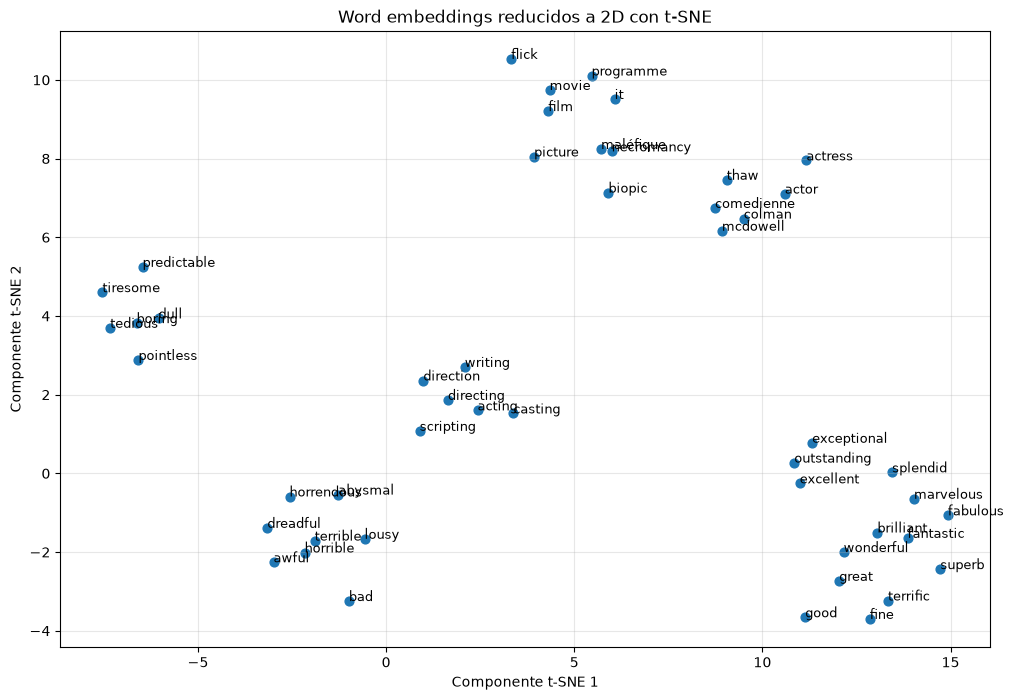

In [75]:
from sklearn.manifold import TSNE
import matplotlib.pyplot as plt

# Palabras que queremos explorar
seed_words = [
    "great", "fantastic", "wonderful", "excellent",
    "bad", "boring", "awful", "terrible",
    "movie", "film", "actor", "acting"
]

# Armamos una lista con cada palabra semilla y sus 5 vecinas más similares
words = []

for seed in seed_words:
    if seed in w2v.wv.key_to_index:
        if seed not in words:
            words.append(seed)

        for word, similarity in w2v.wv.most_similar(seed, topn=5):
            if word not in words:
                words.append(word)

# Embedding de cada palabra: matriz (cantidad_de_palabras, 100)
X_words = np.array([w2v.wv[word] for word in words])

# Reducimos de 100 dimensiones a 2
tsne = TSNE(
    n_components=2,
    perplexity=10,
    init="pca",
    learning_rate="auto",
    random_state=42
)

X_2d = tsne.fit_transform(X_words)

# Graficamos
plt.figure(figsize=(12, 8))
plt.scatter(X_2d[:, 0], X_2d[:, 1], s=40)

for i, word in enumerate(words):
    plt.annotate(word, (X_2d[i, 0], X_2d[i, 1]), fontsize=9)

plt.title("Word embeddings reducidos a 2D con t-SNE")
plt.xlabel("Componente t-SNE 1")
plt.ylabel("Componente t-SNE 2")
plt.grid(alpha=0.3)
plt.show()

3) Entrenar 2 word2vec: uno con las reviews positivas y otro con las negativas. Comparar las distancias entre palabras.


In [78]:
ds_train_pos = train_ds.filter(lambda ex: ex['label'] == 1)
sentences_pos = [tokenize(ex["text"]) for ex in tqdm(ds_train_pos, desc="Tokenizando train positivo")]

w2v_positive = Word2Vec(
        sentences=sentences_pos,
        vector_size=VECTOR_SIZE,
        window=WINDOW,
        min_count=MIN_COUNT,
        workers=WORKERS,
        sg=SG,
        negative=NEGATIVE,
        epochs=EPOCHS_W2V,
    )

print(f"Distancia coseno entre 'good' y 'great': {w2v_positive.wv.similarity("good", "great"):.4f}")
print(f"Distancia coseno entre 'good' y 'accident': {w2v_positive.wv.similarity("good", "accident"):.4f}")
print(f"Distancia coseno entre 'good' y 'bad': {w2v_positive.wv.similarity("good", "bad"):.4f}")

similar_words = w2v_positive.wv.most_similar(positive=["great"], topn=3)
print(f"Palabras similares a 'great': {similar_words}")

Tokenizando train positivo: 100%|██████████| 12500/12500 [00:02<00:00, 5330.77it/s]


Distancia coseno entre 'good' y 'great': 0.7979
Distancia coseno entre 'good' y 'accident': 0.2128
Distancia coseno entre 'good' y 'bad': 0.7039
Palabras similares a 'great': [('wonderful', 0.8634423613548279), ('good', 0.7978677153587341), ('fine', 0.7974081039428711)]


In [79]:
ds_train_neg = train_ds.filter(lambda ex: ex['label'] == 0)
sentences_neg = [tokenize(ex["text"]) for ex in tqdm(ds_train_neg, desc="Tokenizando train negativo")]

w2v_negative = Word2Vec(
        sentences=sentences_neg,
        vector_size=VECTOR_SIZE,
        window=WINDOW,
        min_count=MIN_COUNT,
        workers=WORKERS,
        sg=SG,
        negative=NEGATIVE,
        epochs=EPOCHS_W2V,
    )

print(f"Distancia coseno entre 'good' y 'great': {w2v_negative.wv.similarity("good", "great"):.4f}")
print(f"Distancia coseno entre 'good' y 'accident': {w2v_negative.wv.similarity("good", "accident"):.4f}")
print(f"Distancia coseno entre 'good' y 'bad': {w2v_negative.wv.similarity("good", "bad"):.4f}")

similar_words = w2v_negative.wv.most_similar(positive=["great"], topn=3)
print(f"Palabras similares a 'great': {similar_words}")

Tokenizando train negativo: 100%|██████████| 12500/12500 [00:02<00:00, 6035.25it/s]


Distancia coseno entre 'good' y 'great': 0.7879
Distancia coseno entre 'good' y 'accident': 0.1559
Distancia coseno entre 'good' y 'bad': 0.7477
Palabras similares a 'great': [('good', 0.7879070043563843), ('fine', 0.7288376688957214), ('wonderful', 0.7237545251846313)]


In [80]:
def comparar_similitud(word1, word2):
    print(f"\nSimilitud entre '{word1}' y '{word2}':")

    for nombre, modelo in [("positivas", w2v_positive), ("negativas", w2v_negative)]:
        if word1 in modelo.wv.key_to_index and word2 in modelo.wv.key_to_index:
            sim = modelo.wv.similarity(word1, word2)
            print(f"  Modelo de reseñas {nombre}: {sim:.4f}")
        else:
            print(f"  Modelo de reseñas {nombre}: alguna palabra no está en el vocabulario")

comparar_similitud("good", "great")
comparar_similitud("bad", "boring")
comparar_similitud("good", "bad")


Similitud entre 'good' y 'great':
  Modelo de reseñas positivas: 0.7979
  Modelo de reseñas negativas: 0.7879

Similitud entre 'bad' y 'boring':
  Modelo de reseñas positivas: 0.5778
  Modelo de reseñas negativas: 0.5755

Similitud entre 'good' y 'bad':
  Modelo de reseñas positivas: 0.7039
  Modelo de reseñas negativas: 0.7477
